4.1 және 4.2 бір ұяшықта

In [1]:
import os, time
from pathlib import Path
import torch, ultralytics
from ultralytics import YOLO

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
OUT = PROJECT_ROOT / "data" / "yolo_dataset"
WEIGHTS_DIR = PROJECT_ROOT / "models"
WEIGHTS_DIR.mkdir(exist_ok=True)

print("ultralytics:", ultralytics.__version__, "| torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

os.chdir(WEIGHTS_DIR)                 # салмақ осы қалтаға жүктеледі
model = YOLO("yolo26n.pt")
model.info()
print("✅ Салмақ файлы бар:", (WEIGHTS_DIR / "yolo26n.pt").exists())

img_path = sorted((OUT / "images" / "val").glob("*.jpg"))[0]
print("Сурет:", img_path.name)

torch.cuda.reset_peak_memory_stats()
times = []
for _ in range(6):
    t0 = time.time()
    r = model.predict(str(img_path), device=0, imgsz=640, verbose=False)
    torch.cuda.synchronize()
    times.append((time.time() - t0) * 1000)

print("Әр шақыру (мс):", [round(t, 1) for t in times], "(алғашқысы қыздыру)")
print("Орташа (2-6 шақыру): %.1f мс" % (sum(times[1:]) / 5))
print("GPU жады, ең жоғары: %.2f ГБ" % (torch.cuda.max_memory_allocated() / 1e9))
print("Табылған объект саны:", len(r[0].boxes), "(COCO моделі, жол ақауы емес)")

ultralytics: 8.4.191 | torch: 2.14.1+cu130 | CUDA: True
YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs
✅ Салмақ файлы бар: True
Сурет: Japan_000025.jpg
Әр шақыру (мс): [3667.9, 113.0, 24.0, 22.0, 23.0, 21.0] (алғашқысы қыздыру)
Орташа (2-6 шақыру): 40.6 мс
GPU жады, ең жоғары: 0.07 ГБ
Табылған объект саны: 2 (COCO моделі, жол ақауы емес)


Ұяшық 4.3. 1 эпохалық сынақ оқыту

In [2]:
import time, torch
from pathlib import Path
from ultralytics import YOLO

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
DATA_YAML = PROJECT_ROOT / "configs" / "data.yaml"
RUNS_DIR = PROJECT_ROOT / "runs"

model = YOLO("yolo26n.pt")          # алдын ала оқытылған салмақ
torch.cuda.reset_peak_memory_stats()

t0 = time.time()
results = model.train(
    data=str(DATA_YAML),
    epochs=1,            # сынақ: тек 1 эпоха
    imgsz=640,           # суреттің жағы (пиксель)
    batch=8,             # бір қадамдағы сурет саны (4 ГБ-қа сақ мән)
    device=0,            # бірінші GPU
    workers=2,           # деректерді жүктейтін процестер (Windows-та қиын болса 0)
    patience=10,         # жақсару болмаса тоқтату (1 эпохада әсері жоқ)
    seed=42,
    project=str(RUNS_DIR),
    name="trial_yolo26n_e1",
    exist_ok=True,
)
dt = time.time() - t0

print("\n=== ҚОРЫТЫНДЫ ===")
print("Жалпы уақыт: %.1f мин" % (dt / 60))
print("GPU жады, ең жоғары (PyTorch): %.2f ГБ" % (torch.cuda.max_memory_allocated() / 1e9))
print("Нәтиже қалтасы:", results.save_dir)

New https://pypi.org/project/ultralytics/8.4.198 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.191  Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\road_damage_yolo\configs\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

Ұяшық 4.4. Негізгі оқыту (YOLO26n, 640, 30 эпоха)

In [1]:
import time, torch
from pathlib import Path
from ultralytics import YOLO

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
DATA_YAML = PROJECT_ROOT / "configs" / "data.yaml"
RUNS_DIR = PROJECT_ROOT / "runs"
RUN_NAME = "main_yolo26n_640_e30_s42"

model = YOLO("yolo26n.pt")
torch.cuda.reset_peak_memory_stats()

t0 = time.time()
results = model.train(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=10,
    seed=42,
    amp=False,            # GTX 1650 Ti-де AMP тексеруі сәтсіз болды
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,       # бар қалтаны үстінен жазбайды
)
dt = time.time() - t0

print("\n=== ҚОРЫТЫНДЫ ===")
print("Жалпы уақыт: %.1f мин (%.2f сағат)" % (dt / 60, dt / 3600))
print("GPU жады, ең жоғары: %.2f ГБ" % (torch.cuda.max_memory_allocated() / 1e9))
print("Нәтиже қалтасы:", results.save_dir)

New https://pypi.org/project/ultralytics/8.4.198 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.191  Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\road_damage_yolo\configs\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mo

Ұяшық 4.5. Оқыту қисықтары results.csv бойынша

Бағандар: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2'] 

Соңғы 10 эпоха:
 epoch  metrics/precision(B)  metrics/recall(B)    F1  metrics/mAP50(B)  metrics/mAP50-95(B)
    21                 0.580              0.514 0.545             0.548                0.252
    22                 0.586              0.537 0.560             0.566                0.258
    23                 0.593              0.531 0.560             0.567                0.259
    24                 0.618              0.527 0.569             0.578                0.264
    25                 0.617              0.539 0.575             0.583                0.265
    26                 0.621              0.536 0.575             0.583                0.268
    27                 0.609              0.542 0.574             0.579              

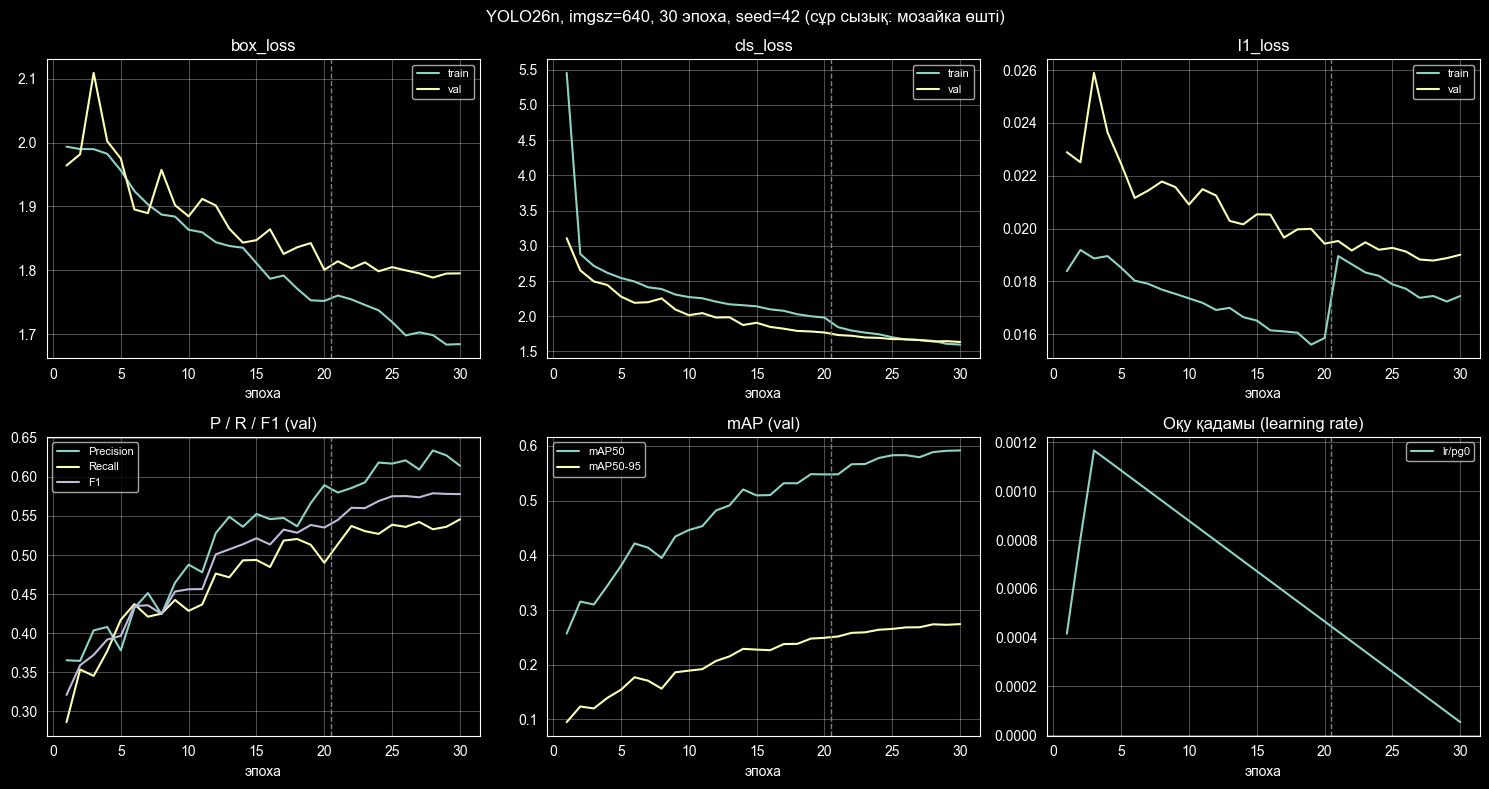

Сақталды: D:\road_damage_yolo\results\figures\main_yolo26n_640_e30_s42_curves.png


In [2]:
# Ұяшық 4.5 — results.csv бойынша оқыту қисықтары
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RUN_DIR = PROJECT_ROOT / "runs" / "main_yolo26n_640_e30_s42"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
TAB_DIR = PROJECT_ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RUN_DIR / "results.csv")
df.columns = df.columns.str.strip()          # атаулардағы бос орындарды алып тастау
print("Бағандар:", list(df.columns), "\n")

# Метрика бағандарын атауының бөлігі бойынша іздеу
def find(part):
    cols = [c for c in df.columns if part in c]
    if not cols:
        raise KeyError(f"'{part}' бар баған табылмады")
    return cols[0]

P, R = find("precision"), find("recall")
M50, M5095 = find("mAP50("), find("mAP50-95")

df["F1"] = 2 * df[P] * df[R] / (df[P] + df[R])

print("Соңғы 10 эпоха:")
print(df[["epoch", P, R, "F1", M50, M5095]].tail(10).round(3).to_string(index=False))

for col in [M50, M5095, "F1"]:
    i = df[col].idxmax()
    print(f"\n{col}: ең жоғары {df.loc[i, col]:.4f}, эпоха {int(df.loc[i, 'epoch'])}")

df.to_csv(TAB_DIR / "main_yolo26n_640_e30_s42_epochs.csv", index=False)

# Графиктер
train_cols = [c for c in df.columns if c.startswith("train/")]
lr_cols = [c for c in df.columns if c.startswith("lr/")]
MOSAIC_OFF = 30 - 10 + 0.5                   # epochs - close_mosaic

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, tc in zip(axes[0], train_cols[:3]):
    name = tc.split("/")[1]
    ax.plot(df["epoch"], df[tc], label="train")
    vc = "val/" + name
    if vc in df.columns:
        ax.plot(df["epoch"], df[vc], label="val")
    ax.set_title(name)

axes[1, 0].plot(df["epoch"], df[P], label="Precision")
axes[1, 0].plot(df["epoch"], df[R], label="Recall")
axes[1, 0].plot(df["epoch"], df["F1"], label="F1")
axes[1, 0].set_title("P / R / F1 (val)")

axes[1, 1].plot(df["epoch"], df[M50], label="mAP50")
axes[1, 1].plot(df["epoch"], df[M5095], label="mAP50-95")
axes[1, 1].set_title("mAP (val)")

for lc in lr_cols[:1]:
    axes[1, 2].plot(df["epoch"], df[lc], label=lc)
axes[1, 2].set_title("Оқу қадамы (learning rate)")

for ax in axes.flat:
    ax.axvline(MOSAIC_OFF, color="gray", ls="--", lw=1)
    ax.set_xlabel("эпоха")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle("YOLO26n, imgsz=640, 30 эпоха, seed=42 (сұр сызық: мозайка өшті)")
fig.tight_layout()
out = FIG_DIR / "main_yolo26n_640_e30_s42_curves.png"
fig.savefig(out, dpi=200)
plt.show()
print("Сақталды:", out)

Ұяшық 4.6. best.pt-ні қайта жүктеу және val нәтижесін қайталау

In [3]:
# Ұяшық 4.6 — best.pt тексеру және val-ды қайталау
import torch
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RUN_DIR = PROJECT_ROOT / "runs" / "main_yolo26n_640_e30_s42"
DATA_YAML = PROJECT_ROOT / "configs" / "data.yaml"
TAB_DIR = PROJECT_ROOT / "results" / "tables"

BEST = RUN_DIR / "weights" / "best.pt"
LAST = RUN_DIR / "weights" / "last.pt"

# 1) best.pt пен last.pt салмақтарын салыстыру
sb = YOLO(str(BEST)).model.state_dict()
sl = YOLO(str(LAST)).model.state_dict()
same = sb.keys() == sl.keys() and all(torch.equal(sb[k], sl[k]) for k in sb)
print("best.pt == last.pt (салмақтар):", same)

# 2) best.pt арқылы val жиынын қайта бағалау
model = YOLO(str(BEST))
metrics = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=True,                       # PR, F1 қисықтары, confusion matrix
    project=str(PROJECT_ROOT / "runs"),
    name="val_main_yolo26n_640_e30_s42",
    exist_ok=True,
)

# 3) Жиынтық және әр класс бойынша кесте
rows = [{"class": "all", "P": metrics.box.mp, "R": metrics.box.mr,
         "mAP50": metrics.box.map50, "mAP50-95": metrics.box.map}]
for i, c in enumerate(metrics.box.ap_class_index):
    p, r, ap50, ap = metrics.box.class_result(i)
    rows.append({"class": metrics.names[int(c)], "P": p, "R": r,
                 "mAP50": ap50, "mAP50-95": ap})

tab = pd.DataFrame(rows)
tab["F1"] = 2 * tab["P"] * tab["R"] / (tab["P"] + tab["R"])
print(tab.round(3).to_string(index=False))
print("Жылдамдық (мс/сурет, батчпен):", {k: round(v, 2) for k, v in metrics.speed.items()})

out = TAB_DIR / "val_main_yolo26n_640_e30_s42_per_class.csv"
tab.to_csv(out, index=False)
print("Сақталды:", out)

best.pt == last.pt (салмақтар): True
Ultralytics 8.4.191  Python-3.12.10 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 431.8±124.5 MB/s, size: 71.0 KB)
val: Scanning D:\road_damage_yolo\data\yolo_dataset\labels\val.cache... 864 images, 79 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 864/864  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 54/54 2.8it/s 19.0s0.3s
                   all        864       1592      0.616      0.545      0.591      0.274
                   D00        275        387      0.619      0.488      0.552      0.243
                   D10        241        440      0.551      0.459      0.506        0.2
                   D20        431        561      0.713      0.665      0.728      0.378
                   D40        145        204       0.58      0.569 